# Лабораторная работа 1 — рабочий ноутбук

**ФИО:**
**Файлы данных:**

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

NAME_CLIENTS = "clients.csv"
NAME_TXN = "transactions.csv"
DATA_PATH = Path("..")/ "data" / "raw"
RAW_CLIENTS = DATA_PATH / NAME_CLIENTS
RAW_TXN = DATA_PATH / NAME_TXN


## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [30]:
df_naiveCLIENTS = pd.read_csv(RAW_CLIENTS)
print('------1------')
df_naiveCLIENTS.info()
print(df_naiveCLIENTS.dtypes.value_counts())
df_naiveCLIENTS.head(15)


------1------
<class 'pandas.DataFrame'>
RangeIndex: 5693 entries, 0 to 5692
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   client_id           5693 non-null   str    
 1   birth_date          5693 non-null   str    
 2   gender              5693 non-null   str    
 3   city                5693 non-null   str    
 4   segment             5693 non-null   str    
 5   loyalty_tier        5693 non-null   str    
 6   card_type           5693 non-null   str    
 7   registration_date   5693 non-null   str    
 8   card_open_date      5693 non-null   str    
 9   income_source       5693 non-null   str    
 10  monthly_income      5140 non-null   float64
 11  has_mobile_app      5693 non-null   str    
 12  app_last_login      3527 non-null   str    
 13  satisfaction_score  2324 non-null   float64
 14  branch_code         5693 non-null   int64  
 15  marketing_opt_in    5693 non-null   str    
dtypes: 

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C001415,1968-12-11,М,СПб,Массовый,Базовый,Дебетовая,16.02.2015,10.06.2019,Не указан,NaN,Нет,NaN,NaN,119,Да
1,C005054,1969-11-01,М,Санкт-Петербург,Массовый,Базовый,Кредитная,22.01.2014,27.07.2016,Не указан,69900.0,Нет,NaN,NaN,707,Нет
2,C005780,1958-01-17,М,г. Москва,Массовый,Серебро,Дебетовая,30.06.2015,18.12.2017,Не указан,NaN,Да,2024-01,NaN,180,Да
3,C003736,1983-04-14,М,Казань,Массовый,Базовый,Дебетовая,18.11.2017,01.01.2022,Не указан,67400.0,Да,2024-07,NaN,681,Да
4,C004260,1972-01-05,М,Новосибирск,Private,Платина,Дебетовая,02.03.2015,03.03.2020,Не указан,481900.0,Да,2025-06,NaN,541,Да
5,C001207,1974-09-09,М,г. Санкт-Петербург,Массовый,Базовый,Дебетовая,26.12.2018,21.06.2022,Не указан,NaN,Да,2024-07,NaN,782,Да
6,C002874,1956-08-24,М,СПб,Зарплатный,Базовый,Дебетовая,17.09.2022,22.04.2025,Зарплата в нашем банке,79400.0,Да,2024-10,NaN,729,Нет
7,C002842,1978-04-05,Ж,Екатеринбург,Премиальный,Серебро,Премиальная,17.03.2022,16.10.2022,Не указан,NaN,Да,2025-02,NaN,898,Нет
8,C001447,1972-07-11,М,Новосибирск,Премиальный,Серебро,Кредитная,02.05.2011,13.07.2016,Не указан,184700.0,Да,2024-12,NaN,874,Да
9,C000948,1963-01-17,Ж,Санкт Петербург,Зарплатный,Серебро,Дебетовая,12.08.2016,13.11.2021,Зарплата в нашем банке,67700.0,Да,2024-07,NaN,563,Нет


In [29]:
df_naiveTXN = pd.read_csv(RAW_TXN, sep=";", decimal=",", encoding="cp1251")
print('------2------')
df_naiveTXN.info()
print(df_naiveTXN.dtypes.value_counts())
df_naiveTXN.head(15)


------2------
<class 'pandas.DataFrame'>
RangeIndex: 619546 entries, 0 to 619545
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   txn_id        619546 non-null  int64  
 1   client_id     619546 non-null  str    
 2   txn_datetime  619546 non-null  str    
 3   amount        619546 non-null  float64
 4   currency      619546 non-null  str    
 5   category      619546 non-null  str    
 6   mcc_code      619546 non-null  int64  
 7   channel       619546 non-null  str    
 8   status        619546 non-null  str    
dtypes: float64(1), int64(2), str(6)
memory usage: 42.5 MB
str        6
int64      2
float64    1
Name: count, dtype: int64


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990216,C005663,2023-11-23 07:34:48,400.62,RUB,Продукты,5411,Карта,успешно
1,990148,C000040,2023-11-24 09:30:21,409.56,RUB,Аптеки,5912,Карта,успешно
2,990075,C000672,2023-11-25 12:28:16,2448.23,RUB,Развлечения и досуг,7832,Карта,успешно
3,990052,C003352,2023-11-27,1131.33,RUB,Продукты,5411,Карта,успешно
4,990014,C001511,2023-11-29 15:12:23,262.17,RUB,Онлайн-сервисы,5815,Карта,успешно
5,990188,C005914,2023-12-05 19:58:07,601.83,RUB,Продукты,5411,Карта,успешно
6,990053,C004843,2023-12-26 10:16:59,1909.58,RUB,Одежда и обувь,5651,Онлайн-банк,успешно
7,990143,C004526,2023-12-28 11:10:31,774.44,RUB,Продукты,5411,Онлайн-банк,успешно
8,990088,C000376,2023-12-28 16:31:44,736.69,RUB,Онлайн-сервисы,5815,Карта,успешно
9,100001,C003677,2024-01-01 00:53:52,3008.67,RUB,Продукты,5411,Карта,успешно


In [ ]:
SATISFACTION_SCORE_ORDER = pd.CategoricalDtype(["1", "2", "3", "4", "5"], ordered=True)
LOYALTY_TIER_ORDER = pd.CategoricalDtype(["Базовый", "Серебро", "Золото", "Платина"], ordered=True)

DTYPES_CLIENTS = {
    "client_id" : "string",
    "gender" : "category",
    "city" : "string",
    "segment" : "category",
    "loyalty_tier" : LOYALTY_TIER_ORDER,
    "card_type" : "category",
    "income_source" : "string",
    "monthly_income": "float64",
    "has_mobile_app" : "category",
    "satisfaction_score" : SATISFACTION_SCORE_ORDER,
    "branch_code" : "Int64",
    "marketing_opt_in" : "category"
}
df1 = pd.read_csv(RAW_CLIENTS, dtype = DTYPES_CLIENTS, parse_dates = ["birth_date", "registration_date", "card_open_date", "app_last_login"], 
date_format = {"birth_date" :"%Y-%m-%d","registration_date" :"%d.%m.%Y", "card_open_date" : "%d.%m.%Y", "app_last_login": "%Y-%m"  })

DTYPES_TXN = {
    "txn_id" : "Int64",
    "client_id" : "string",
    "amount" : "float64",
    "currency" : "category",
    "category" : "category",
    "mcc_code" : "category",
    "channel": "category",
    "status" : "category",
}

df2 = pd.read_csv(RAW_TXN, dtype = DTYPES_TXN, parse_dates = ["txn_datetime"], 
date_format = {"txn_datetime": "%Y-%m-%d %H:%M:%S"}, sep=";", decimal=",", encoding="cp1251" )



## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [36]:
print("Размеры таблицы")
print(df1.shape)
print("Типы таблицы")
print(df1.dtypes)
print("-----1----")
print(df1.dtypes.value_counts())
print("Пропущенные ключи(кол-во):")
print(df1["client_id"].isna().sum())
print("Уникальных ключей: ")
print(df1["client_id"].nunique())
print("Повторы ключей")
print(df1["client_id"].duplicated().sum())

Размеры таблицы
(5693, 16)
Типы таблицы
client_id                     string
birth_date            datetime64[us]
gender                      category
city                          string
segment                     category
loyalty_tier                category
card_type                   category
registration_date     datetime64[us]
card_open_date        datetime64[us]
income_source                 string
monthly_income               float64
has_mobile_app              category
app_last_login        datetime64[us]
satisfaction_score          category
branch_code                    Int64
marketing_opt_in            category
dtype: object
-----1----
datetime64[us]    4
string            3
category          2
category          1
category          1
category          1
category          1
float64           1
category          1
Int64             1
Name: count, dtype: int64
Пропущенные ключи(кол-во):
0
Уникальных ключей: 
5638
Повторы ключей
55


Единицей наблюдения будем считать одного клиента с уникальными значением client_id. Все типы успешно преобразованы к нужным 

In [37]:
print("Размеры таблицы")
print(df2.shape)
print("Типы таблицы")
print(df2.dtypes)
print("-----1----")
print(df2.dtypes.value_counts())
print("Пропущенные ключи(кол-во):")
print(df2["txn_id"].isna().sum())
print("Уникальных ключей: ")
print(df2["txn_id"].nunique())
print("Повторы ключей")
print(df2["txn_id"].duplicated().sum())

Размеры таблицы
(619546, 9)
Типы таблицы
txn_id             Int64
client_id         string
txn_datetime         str
amount           float64
currency        category
category        category
mcc_code        category
channel         category
status          category
dtype: object
-----1----
Int64       1
string      1
str         1
float64     1
category    1
category    1
category    1
category    1
category    1
Name: count, dtype: int64
Пропущенные ключи(кол-во):
0
Уникальных ключей: 
618046
Повторы ключей
1500


### 2.2. Дубли

In [12]:
print("-----2Дублированных ключей----")
mask_df1_dupID = df1["client_id"].duplicated(keep=False)
df1_dupID =df1[mask_df1_dupID] 
print(df1_dupID)
print("-----3 Полностью Дублированных ----")
mask_df1_dupFull = df1.duplicated(keep=False)
df1_dupFull = df1[mask_df1_dupFull]
print(df1_dupFull)
print("-----4 Дублированных ключей - Полностью Дублированных ----")
df1_oneRogue = df1[mask_df1_dupID & ~mask_df1_dupFull].sort_values("client_id")
print(df1_oneRogue)
print(sum(mask_df1_dupID & ~mask_df1_dupFull))

-----2Дублированных ключей----
     client_id birth_date gender                city      segment loyalty_tier    card_type registration_date card_open_date            income_source  \
140    C005996 1967-08-30      Ж         Н. Новгород     Массовый      Базовый    Дебетовая        2015-02-07     2020-06-06                Не указан   
143    C002006 1965-04-28      М  г. Санкт-Петербург  Премиальный      Серебро    Дебетовая        2017-07-18     2020-05-30   Зарплата в нашем банке   
234    C000106 1976-03-30      Ж              МОСКВА  Премиальный       Золото  Премиальная        2015-12-15     2021-05-09  Зарплата в другом банке   
375    C004630 1974-08-21      М         Новосибирск     Массовый      Базовый    Кредитная        2019-07-05     2024-12-02  Зарплата в другом банке   
434    C002399 1987-07-25      Ж              Казань     Массовый      Базовый    Кредитная        2014-05-10     2019-11-27  Зарплата в другом банке   
...        ...        ...    ...                 ..

In [38]:
print("-----2Дублированных ключей----")
mask_df2_dupID = df2["txn_id"].duplicated(keep=False)
df2_dupID =df2[mask_df2_dupID] 
print(df2_dupID)
print("-----3 Полностью Дублированных ----")
mask_df2_dupFull = df2.duplicated(keep=False)
df2_dupFull = df2[mask_df2_dupFull]
print(df2_dupFull)
print("-----4 Дублированных ключей - Полностью Дублированных ----")
df2_oneRogue = df2[mask_df2_dupID & ~mask_df2_dupFull].sort_values("txn_id")
print(df2_oneRogue)
print(sum(mask_df2_dupID & ~mask_df2_dupFull))

-----2Дублированных ключей----
        txn_id client_id         txn_datetime   amount currency          category mcc_code      channel   status
130     100122   C005016  2024-01-01 09:59:16    36.64      RUB         Транспорт     4111        Карта  успешно
131     100122   C005016  2024-01-01 09:59:16    36.64      RUB         Транспорт     4111        Карта  успешно
214     100205   C005356  2024-01-01 11:36:24  1421.49      RUB  кафе и рестораны     5812          СБП  успешно
215     100205   C005356  2024-01-01 11:36:24  1421.49      RUB  кафе и рестораны     5812          СБП  успешно
580     100569   C001541  2024-01-01 17:55:16  3603.85      RUB    Одежда и обувь     5651          СБП  успешно
...        ...       ...                  ...      ...      ...               ...      ...          ...      ...
617830  720375   C002741  2025-06-29 12:09:36   484.06      RUB               АЗС     5541        Токен  успешно
617866  720411   C003498  2025-06-29 12:39:25   806.71      RUB  

### 2.3. Соответствие данных описанию полей из задания

In [39]:
print(df1.dtypes)
print('------------')
print(df1['gender'].value_counts(dropna=False))
print('------------')
print(df1['segment'].value_counts(dropna=False))
print('------------')
print(df1['loyalty_tier'].value_counts(dropna=False))
print('------------')
print(df1['card_type'].value_counts(dropna=False))
print('------------')
print(df1['has_mobile_app'].value_counts(dropna=False))
print('------------')
print(df1['satisfaction_score'].value_counts(dropna=False))
print('------------')
print(df1['marketing_opt_in'].value_counts(dropna=False))
print('------------')
print(df1['city'].value_counts(dropna=False))
print('------------')
print(df1['income_source'].value_counts(dropna=False))
df1.head(20)

client_id                     string
birth_date            datetime64[us]
gender                      category
city                          string
segment                     category
loyalty_tier                category
card_type                   category
registration_date     datetime64[us]
card_open_date        datetime64[us]
income_source                 string
monthly_income               float64
has_mobile_app              category
app_last_login        datetime64[us]
satisfaction_score          category
branch_code                    Int64
marketing_opt_in            category
dtype: object
------------
gender
М    2924
Ж    2769
Name: count, dtype: int64
------------
segment
Массовый       2894
Зарплатный     1670
Премиальный     912
Private         217
Name: count, dtype: int64
------------
loyalty_tier
Базовый    2864
Серебро    1555
Золото      964
Платина     310
Name: count, dtype: int64
------------
card_type
Дебетовая      3927
Кредитная      1282
Премиальная     484
Na

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C001415,1968-12-11,М,СПб,Массовый,Базовый,Дебетовая,2015-02-16,2019-06-10,Не указан,NaN,Нет,NaT,NaN,119,Да
1,C005054,1969-11-01,М,Санкт-Петербург,Массовый,Базовый,Кредитная,2014-01-22,2016-07-27,Не указан,69900.0,Нет,NaT,NaN,707,Нет
2,C005780,1958-01-17,М,г. Москва,Массовый,Серебро,Дебетовая,2015-06-30,2017-12-18,Не указан,NaN,Да,2024-01-01,NaN,180,Да
3,C003736,1983-04-14,М,Казань,Массовый,Базовый,Дебетовая,2017-11-18,2022-01-01,Не указан,67400.0,Да,2024-07-01,NaN,681,Да
4,C004260,1972-01-05,М,Новосибирск,Private,Платина,Дебетовая,2015-03-02,2020-03-03,Не указан,481900.0,Да,2025-06-01,NaN,541,Да
5,C001207,1974-09-09,М,г. Санкт-Петербург,Массовый,Базовый,Дебетовая,2018-12-26,2022-06-21,Не указан,NaN,Да,2024-07-01,NaN,782,Да
6,C002874,1956-08-24,М,СПб,Зарплатный,Базовый,Дебетовая,2022-09-17,2025-04-22,Зарплата в нашем банке,79400.0,Да,2024-10-01,NaN,729,Нет
7,C002842,1978-04-05,Ж,Екатеринбург,Премиальный,Серебро,Премиальная,2022-03-17,2022-10-16,Не указан,NaN,Да,2025-02-01,NaN,898,Нет
8,C001447,1972-07-11,М,Новосибирск,Премиальный,Серебро,Кредитная,2011-05-02,2016-07-13,Не указан,184700.0,Да,2024-12-01,NaN,874,Да
9,C000948,1963-01-17,Ж,Санкт Петербург,Зарплатный,Серебро,Дебетовая,2016-08-12,2021-11-13,Зарплата в нашем банке,67700.0,Да,2024-07-01,NaN,563,Нет


### 2.4. Связь между таблицами

In [ ]:
print("-----Неизвестные клиенты, их транзакции------")
unknown_client = ( df2["client_id"].notna() & ~df2["client_id"].isin(df1["client_id"]))
print(unknown_client.sum())
print(df2[unknown_client])
print("-----Неизвестные клиенты------")
print("Кол-во")
print(df2.loc[unknown_client, "client_id"].nunique())
print("id_client")
print(df2.loc[unknown_client, "client_id"].unique())

-----Неизвестные клиенты, их транзакции------
29639
        txn_id client_id         txn_datetime    amount currency             category mcc_code channel     status
8       990088   C000376  2023-12-28 16:31:44    736.69      RUB       Онлайн-сервисы     5815   Карта    успешно
10      100002   C001142  2024-01-01 02:33:55    299.47      RUB     Связь и интернет     4814     СБП    успешно
38      100030   C000946  2024-01-01 06:43:37   2494.59      RUB       Одежда и обувь     5651   Токен    успешно
43      100035   C003516  2024-01-01 07:00:25    800.20      RUB             Продукты     5411     СБП    успешно
44      100036   C001491  2024-01-01 07:04:46    831.42      RUB     Кафе и рестораны     5812   Токен    успешно
...        ...       ...                  ...       ...      ...                  ...      ...     ...        ...
526671  629464   C001410  2025-03-31 18:47:04    471.62      RUB               Аптеки     5912   Карта    успешно
526740  629535   C004642  2025-03-31

In [65]:
print("-------Клиенты без транзацкий --------")
clients_NOtxn = (df1["client_id"].notna() & ~df1["client_id"].isin(df2["client_id"]))
print(clients_NOtxn.sum())
print(df1[clients_NOtxn])

-------Клиенты без транзацкий --------
12
     client_id birth_date gender                city      segment loyalty_tier    card_type registration_date card_open_date            income_source  \
1156   C000205 1956-08-28      Ж     Санкт Петербург     Массовый      Базовый    Кредитная        2024-11-17     2025-05-13  Зарплата в другом банке   
1184   C000148 1967-08-14      Ж         Новосибирск   Зарплатный      Базовый    Дебетовая        2020-12-10     2025-03-31   Зарплата в нашем банке   
1281   C004130 1992-06-23      М  г. Санкт-Петербург     Массовый      Базовый    Дебетовая        2023-03-29     2025-03-24                Не указан   
2142   C002450 1946-08-28      М     Санкт Петербург     Массовый       Золото    Дебетовая        2019-11-21     2025-03-25  Зарплата в другом банке   
2253   C002639 1971-06-20      Ж              МОСКВА  Премиальный       Золото  Премиальная        2021-02-03     2025-03-31                Не указан   
2837   C002066 1945-06-18      Ж        

**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### 3.1. Типы, даты, числа

прожиточный минимум сотсавляет = 16000, вот уже точки ниже странно смотрятся
city
Москва             1691
Санкт-Петербург     968
Нижний Новгород     908
Казань              709
Новосибирск         709
Екатеринбург        708
Name: count, dtype: Int64
  client_id birth_date gender             city   segment loyalty_tier  card_type registration_date card_open_date income_source  monthly_income  \
0   C001415 1968-12-11      М  Санкт-Петербург  Массовый      Базовый  Дебетовая        2015-02-16     2019-06-10     Не указан            <NA>   
1   C005054 1969-11-01      М  Санкт-Петербург  Массовый      Базовый  Кредитная        2014-01-22     2016-07-27     Не указан           69900   
2   C005780 1958-01-17      М           Москва  Массовый      Серебро  Дебетовая        2015-06-30     2017-12-18     Не указан            <NA>   
3   C003736 1983-04-14      М           Казань  Массовый      Базовый  Дебетовая        2017-11-18     2022-01-01     Не указан           67400   
4   C004260 1

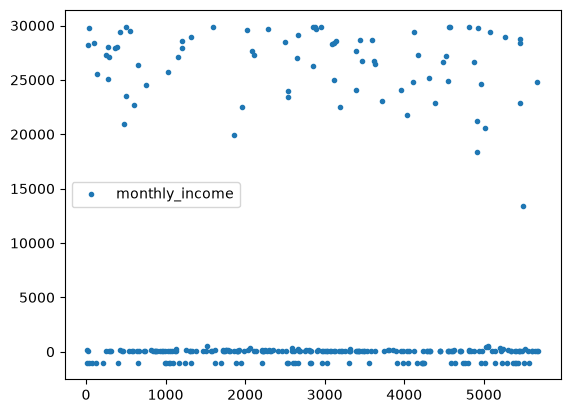

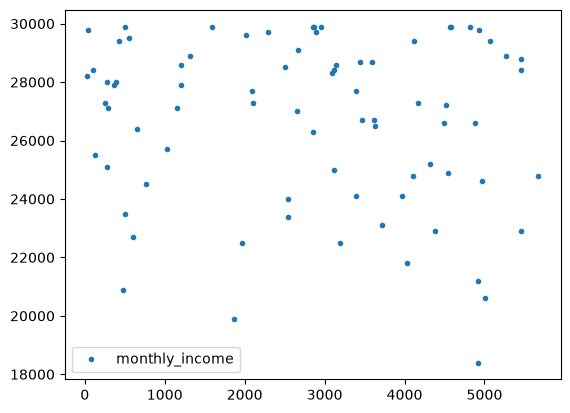

In [ ]:
df1[df1["monthly_income"]<30_000].plot(y ="monthly_income", style = ".")
print("прожиточный минимум сотсавляет = 16000, вот уже точки ниже странно смотрятся")

df1FIX.loc[df1FIX["monthly_income"] < 16_000, "monthly_income"] = np.nan
df1FIX[df1FIX["monthly_income"]<30_000].plot(y ="monthly_income", style = ".")
df1FIX["monthly_income"] = df1FIX["monthly_income"].astype("Int64")
print(df1FIX.head())

### 3.2. Категориальные признаки

In [ ]:
CITY_FIX = {
    " москва":"Москва",
    "г. Москва":"Москва",
    "МОСКВА":"Москва",
    "Н. Новгород":"Нижний Новгород",
    "Санкт Петербург":"Санкт-Петербург",
    "г. Санкт-Петербург":"Санкт-Петербург",
    "казань":"Казань",
    "г. Новосибирск":"Новосибирск",
    "СПб":"Санкт-Петербург",
    "ЕКАТЕРИНБУРГ":"Екатеринбург",
    "г.Екатеринбург":"Екатеринбург"
}

df1FIX = df1.copy()
df1FIX["city"] = df1FIX["city"].replace(CITY_FIX)
print(df1FIX["city"].value_counts(dropna=False))

### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

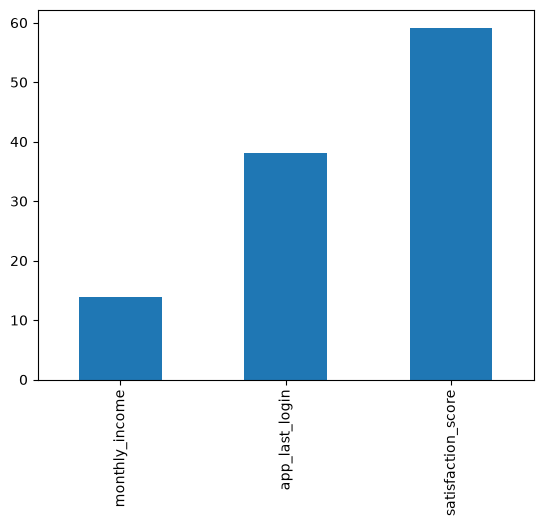

In [30]:
missing = df1FIX.isna().mean()*100
missing = missing[missing>0].plot.bar()

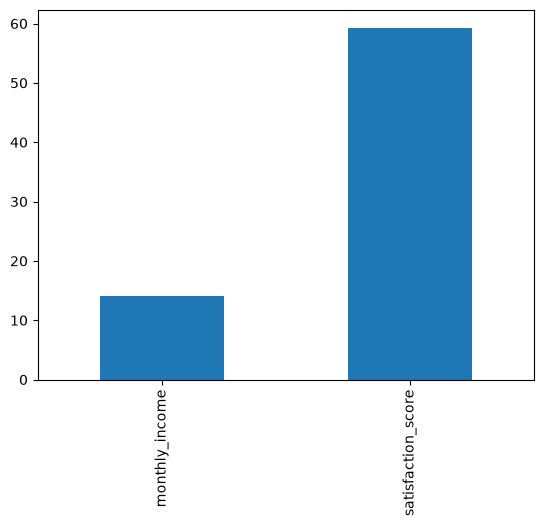

In [31]:
df1VIEW =df1FIX[df1FIX["has_mobile_app"] == "Да"] 
missing = df1VIEW.isna().mean()*100
missing = missing[missing>0].plot.bar()

<Axes: xlabel='segment'>

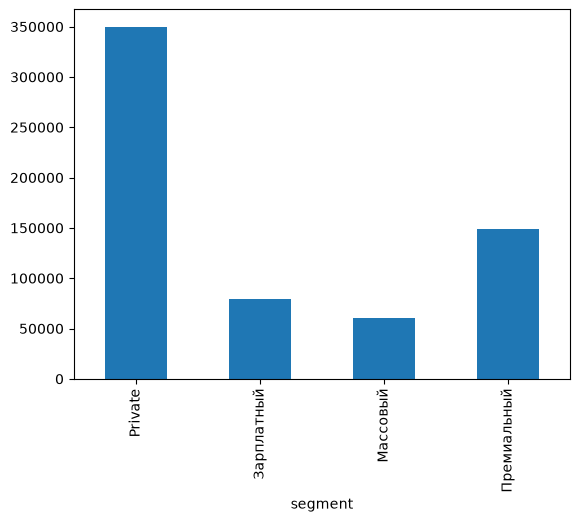

### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [ ]:
cleaning_log = pd.DataFrame(columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])

## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

### 5.2. Частотные характеристики категориальных признаков

### 5.3. Динамика по месяцам

### 5.4. Разрезы и связи между признаками

In [ ]:
df1FIX.groupby("segment")["monthly_income"].median().plot.bar()

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

### 7.1. Кого в кампанию не берём и почему

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [ ]:
# clean.to_parquet("clean_data.parquet", index=False)
# cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
# campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")